## Data Preprocessing

import libraries and settings

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Image resize dimensions
image_size = (224, 224)

# Batch size
batch_size = 32

# Your dataset directory (update if needed)
dataset_path = "../dataset_8"

In [ ]:
train_data_generator = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,          # Normalise pixel values to [0, 1]
    validation_split=0.3     
)

create training & validation generator

In [5]:
training_generator = train_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42  # for reproducibility
)

validation_generator = train_data_generator.flow_from_directory(
    dataset_path,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=False,
    seed=42  # for reproducibility
)

Found 336 images belonging to 4 classes.
Found 144 images belonging to 4 classes.


In [6]:
print(f"Training samples: {training_generator.samples}")
print(f"Validation samples: {validation_generator.samples}")
print(f"Number of classes: {training_generator.num_classes}")
print(f"Class indices: {training_generator.class_indices}")

Training samples: 336
Validation samples: 144
Number of classes: 4
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


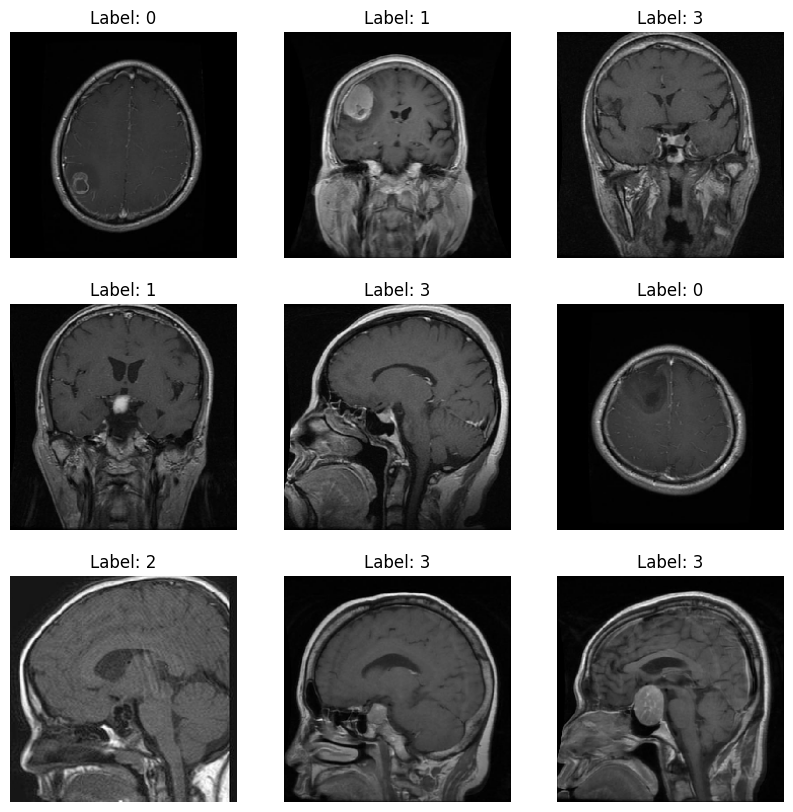

In [7]:
images, labels = next(training_generator)

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(images[i])
    plt.title(f"Label: {np.argmax(labels[i])}")
    plt.axis('off')
plt.show()